In [1]:
###############################################################################
####### creating the plots of the city wide predictions for the ML paper ######
###############################################################################


import numpy as np
import pandas as pd
import math
import datetime
import os
import matplotlib.pyplot as plt

# all_data_df - dataset containing precipitation, this is just used to generate the rain volume heatmap
all_data_df = pd.read_csv(r"C:/Users/Sarah/Documents/Python_Scripts/DDL/SOLWEIG/rasters_for_eric/input_sensitivity_runs/solweig_met_input_data.csv")

# 
ml_at_data_path = r"D:\DDL\Durham_ML\Absolute\Clipped\Summary_Rasters\Hourly_stats_csvs/Predictions_AT_hourly_city_stats.csv"
ml_rh_data_path = r"D:\DDL\Durham_ML\Absolute\Clipped\Summary_Rasters\Hourly_stats_csvs/Predictions_RH_hourly_city_stats.csv"
ml_hi_data_path = r"D:\DDL\Durham_ML\Absolute\Clipped\Summary_Rasters\Hourly_stats_csvs/Predictions_HI_C_hourly_city_stats.csv"

at_stats_df = pd.read_csv(ml_at_data_path)
rh_stats_df = pd.read_csv(ml_rh_data_path)
hi_stats_df = pd.read_csv(ml_hi_data_path)

# add in hour
at_stats_df['Hour'] = pd.to_datetime(at_stats_df['timestamp']).dt.hour
rh_stats_df['Hour'] = pd.to_datetime(rh_stats_df['timestamp']).dt.hour
hi_stats_df['Hour'] = pd.to_datetime(hi_stats_df['timestamp']).dt.hour
#add in ranges 
at_stats_df['range'] = at_stats_df['max'] - at_stats_df['min']
rh_stats_df['range'] = rh_stats_df['max'] - rh_stats_df['min']
hi_stats_df['range'] = hi_stats_df['max'] - hi_stats_df['min']
# hourly means
hourly_summary_at = at_stats_df.groupby('Hour').mean(numeric_only=True).reset_index()
hourly_summary_rh = rh_stats_df.groupby('Hour').mean(numeric_only=True).reset_index()
hourly_summary_hi = hi_stats_df.groupby('Hour').mean(numeric_only=True).reset_index()

In [2]:
#### Prediction intervals, can skip ####

# get the model prediction intervals to add in/ compare 
at_pred_intervals_path = r'C:\Users/Sarah/Documents/Python_Scripts/DDL/Sensor_Network/Heat_model_Durham_Raleigh/src/model_training/SB/results/AT_hourly_summary.csv'
at_pred_intervals = pd.read_csv(at_pred_intervals_path)

at_pred_intervals['resid_upper'] = at_pred_intervals['PI_upper'] - at_pred_intervals['Temperature']
at_pred_intervals['resid_lower'] = at_pred_intervals['Temperature'] - at_pred_intervals['PI_lower']
hourly_summary_at['PI_upper'] = hourly_summary_at['mean']+at_pred_intervals['resid_upper']
hourly_summary_at['PI_lower'] = hourly_summary_at['mean']-at_pred_intervals['resid_lower']

In [3]:
hourly_summary_at['PI_lower'] = hourly_summary_at['mean'] - [1.09016946, 1.03761859, 0.9645919 , 0.95734396, 0.92714394,
       0.8919598 , 0.88759259, 0.87014042, 1.35195773, 1.98121401,
       2.01623779, 1.93675456, 1.84457345, 1.78324559, 2.02942572,
       2.23748205, 2.31939772, 1.90991372, 1.6209412 , 1.49485477,
       1.19887732, 1.19124206, 1.18996477, 1.13646878]


hourly_summary_at['PI_upper'] = hourly_summary_at['mean'] - [-1.3414557 , -1.23429013, -1.16104908, -1.09845536, -1.06439924,
       -1.01958845, -0.98540486, -0.96147049, -1.35450905, -2.5026908 ,
       -2.7840661 , -2.29883414, -2.12047926, -1.79925086, -1.81121021,
       -1.86289599, -2.14071645, -2.57613164, -2.55193964, -2.09553443,
       -1.55754425, -1.49302153, -1.48463256, -1.45051767]

In [4]:
mins_hourly_summary_at = at_stats_df.groupby('Hour').min(numeric_only=True).reset_index()
maxs_hourly_summary_at = at_stats_df.groupby('Hour').max(numeric_only=True).reset_index()
stds_hourly_summary_at = at_stats_df.groupby('Hour').std(numeric_only=True).reset_index()

mins_hourly_summary_rh = rh_stats_df.groupby('Hour').min(numeric_only=True).reset_index()
maxs_hourly_summary_rh = rh_stats_df.groupby('Hour').max(numeric_only=True).reset_index()
stds_hourly_summary_rh = rh_stats_df.groupby('Hour').std(numeric_only=True).reset_index()

In [5]:
## Create a heatmap
at_stats_df["timestamp"] = pd.to_datetime(at_stats_df["timestamp"])
at_stats_df["date"] = at_stats_df["timestamp"].dt.date
at_stats_df["hour"] = at_stats_df["timestamp"].dt.hour

rh_stats_df["timestamp"] = pd.to_datetime(rh_stats_df["timestamp"])
rh_stats_df["date"] = rh_stats_df["timestamp"].dt.date
rh_stats_df["hour"] = rh_stats_df["timestamp"].dt.hour

hi_stats_df["timestamp"] = pd.to_datetime(hi_stats_df["timestamp"])
hi_stats_df["date"] = hi_stats_df["timestamp"].dt.date
hi_stats_df["hour"] = hi_stats_df["timestamp"].dt.hour

#create pivot table
heatmap_at = at_stats_df.pivot_table(index="date", columns="hour", values="range")
heatmap_rh = rh_stats_df.pivot_table(index="date", columns="hour", values="range")
heatmap_hi = hi_stats_df.pivot_table(index="date", columns="hour", values="range")

In [6]:
print('AT Min Max Range:', at_stats_df.range.min(), at_stats_df.range.max())
print('RH Min Max Range:', rh_stats_df.range.min(), rh_stats_df.range.max())
print('HI Min Max Range:', hi_stats_df.range.min(), hi_stats_df.range.max())

print('AT Min Max Mean:', at_stats_df['mean'].min(), at_stats_df['mean'].max())
print('RH Min Max Mean:', rh_stats_df['mean'].min(), rh_stats_df['mean'].max())
print('HI Min Max Mean:', hi_stats_df['mean'].min(), hi_stats_df['mean'].max())

AT Min Max Range: 0.5158830000000023 8.613475999999999
RH Min Max Range: 0.8731300000000033 45.223235
HI Min Max Range: 0.595046 15.081741000000001
AT Min Max Mean: 12.892028 36.75866
RH Min Max Mean: 33.48774 99.97945
HI Min Max Mean: 12.687011 43.604797


In [7]:
print('AT Min Max Mean:', at_stats_df['mean'].min(), at_stats_df['mean'].max())
print('RH Min Max Mean:', rh_stats_df['mean'].min(), rh_stats_df['mean'].max())
print('HI Min Max Mean:', hi_stats_df['mean'].min(), hi_stats_df['mean'].max())

AT Min Max Mean: 12.892028 36.75866
RH Min Max Mean: 33.48774 99.97945
HI Min Max Mean: 12.687011 43.604797


In [8]:
at_stats_df[at_stats_df['max'] == at_stats_df['max'].max() ]

,timestamp,mean,min,max,Hour,range,date,hour
89,2024-07-04 17:00:00,36.75866,34.827763,39.50022,17,4.672457,2024-07-04,17


In [10]:
rh_stats_df[rh_stats_df['timestamp'] == '2024-07-04 17:00:00' ]

,timestamp,mean,min,max,Hour,range,date,hour
89,2024-07-04 17:00:00,38.578587,31.266636,50.446312,17,19.179676,2024-07-04,17


In [11]:
hi_stats_df[hi_stats_df['timestamp'] == '2024-07-04 17:00:00' ]

,timestamp,mean,min,max,Hour,range,date,hour
89,2024-07-04 17:00:00,40.15091,37.750385,44.47998,17,6.729595,2024-07-04,17


In [12]:
hi_stats_df[hi_stats_df['max'] == hi_stats_df['max'].max() ]

,timestamp,mean,min,max,Hour,range,date,hour
113,2024-07-05 17:00:00,43.604797,38.578228,51.49658,17,12.918352,2024-07-05,17


In [13]:
at_stats_df[at_stats_df['timestamp'] == '2024-07-05 17:00:00' ]

,timestamp,mean,min,max,Hour,range,date,hour
113,2024-07-05 17:00:00,34.076447,30.391262,38.74636,17,8.355098,2024-07-05,17


In [14]:
at_stats_df[at_stats_df['min'] == at_stats_df['min'].min() ]

,timestamp,mean,min,max,Hour,range,date,hour
1255,2024-08-22 07:00:00,12.892028,11.63206,14.914857,7,3.282797,2024-08-22,7


In [15]:
rh_stats_df[rh_stats_df['timestamp'] == '2024-08-22 07:00:00' ]

,timestamp,mean,min,max,Hour,range,date,hour
1255,2024-08-22 07:00:00,93.8384,82.58877,100.0,7,17.41123,2024-08-22,7


In [16]:
hi_stats_df[hi_stats_df['timestamp'] == '2024-08-22 07:00:00' ]

,timestamp,mean,min,max,Hour,range,date,hour
1255,2024-08-22 07:00:00,12.687011,11.399349,14.672143,7,3.272794,2024-08-22,7


In [10]:
all_data_df["timestamp"] = pd.to_datetime(all_data_df["timestamp"])
all_data_df["date"] = all_data_df["timestamp"].dt.date
all_data_df["hour"] = all_data_df["timestamp"].dt.hour
rain_vol =  all_data_df[["date","hour",'total_precipitation_hourly']].copy()
#turn precip to mm per hour
rain_vol['total_precipitation_hourly_mm'] = 1000*rain_vol['total_precipitation_hourly']
heatmap_rain_vol = rain_vol.pivot_table(index="date", columns="hour", values="total_precipitation_hourly_mm")


In [11]:
import matplotlib.gridspec as gridspec

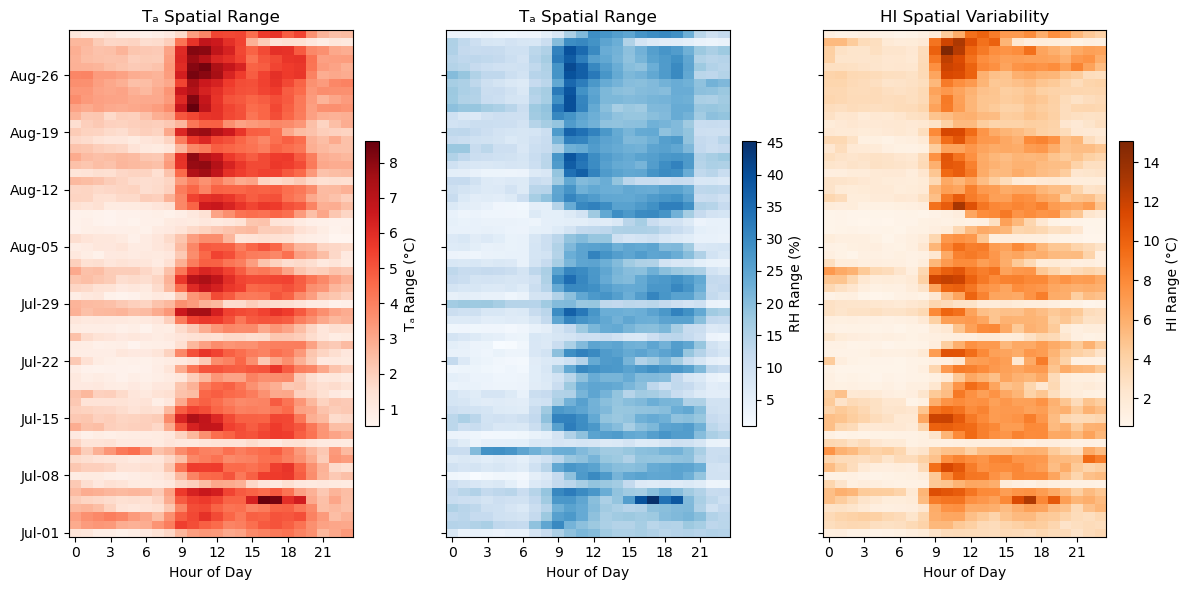

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(12, 6), sharey=True)

# AT
im1 = axes[0].imshow(
    heatmap_at,
    aspect="auto",
    cmap="Reds",
    origin="lower",
    interpolation="nearest"
)
axes[0].set_title("Tₐ Spatial Range")
axes[0].set_xlabel("Hour of Day")
#axes[0].set_ylabel("Date")
axes[0].set_xticks(range(0, 24, 3))
axes[0].set_yticks(range(0, len(heatmap_at.index), 7))
axes[0].set_yticklabels([str(d.strftime("%b-%d")) for d in heatmap_at.index[::7]])



# RH
im2 = axes[1].imshow(
    heatmap_rh,
    aspect="auto",
    cmap="Blues",
    origin="lower",
    interpolation="nearest"
)
axes[1].set_title("Tₐ Spatial Range")
axes[1].set_xlabel("Hour of Day")
axes[1].set_xticks(range(0, 24, 3))

# HI
im3 = axes[2].imshow(
    heatmap_hi,
    aspect="auto",
    cmap="Oranges",
    origin="lower",
    interpolation="nearest"
)
axes[2].set_title("HI Spatial Variability")
axes[2].set_xlabel("Hour of Day")
axes[2].set_xticks(range(0, 24, 3))


# colorbars 
cbar1 = fig.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04)
cbar1.set_label("Tₐ Range (°C)")
cbar2 = fig.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04)
cbar2.set_label("RH Range (%)")
cbar3 = fig.colorbar(im3, ax=axes[2], fraction=0.046, pad=0.04)
cbar3.set_label("HI Range (°C)")
plt.tight_layout()



In [13]:
from matplotlib.ticker import MultipleLocator

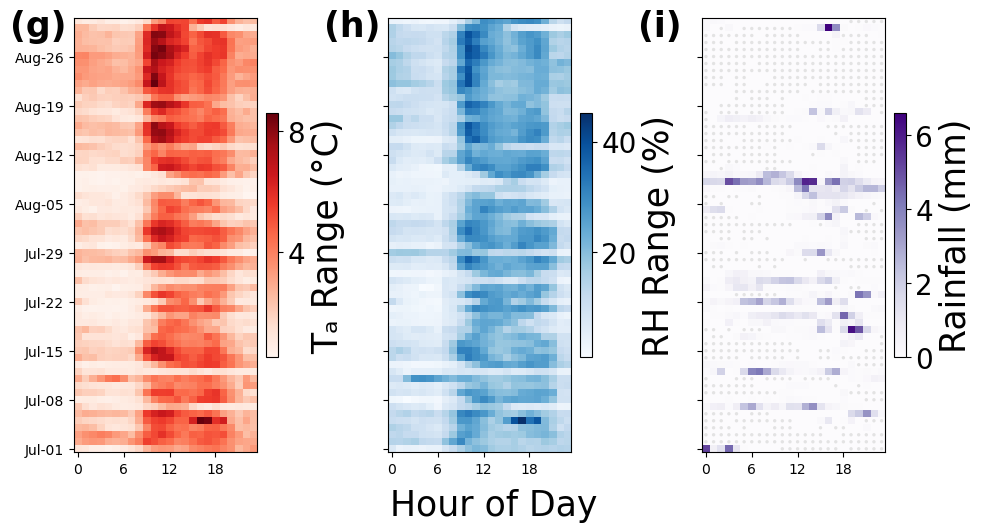

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(10, 5), sharey=True)
plt.rcParams.update({
    'font.size': 14,
    'axes.titlesize': 25,
    'axes.labelsize': 25,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20
})
# AT
im1 = axes[0].imshow(
    heatmap_at,
    aspect="auto",
    cmap="Reds",
    origin="lower",
    interpolation="nearest"
)
#axes[0].set_title("Tₐ Spatial Range")
#axes[0].set_xlabel("Hour of Day")
#axes[0].set_ylabel("Date")
axes[0].set_xticks(range(0, 24, 6))
axes[0].set_yticks(range(0, len(heatmap_at.index), 7))
axes[0].set_yticklabels([str(d.strftime("%b-%d")) for d in heatmap_at.index[::7]])

# RH
im2 = axes[1].imshow(
    heatmap_rh,
    aspect="auto",
    cmap="Blues",
    origin="lower",
    interpolation="nearest"
)
#axes[1].set_title("RH Spatial Range")
#axes[1].set_xlabel("Hour of Day")
axes[1].set_xticks(range(0, 24, 6))


#rain vol

im3 = axes[2].imshow(
    heatmap_rain_vol,
    aspect="auto",
    cmap='Purples',
    origin="lower",
    interpolation="nearest",

    
)
#axes[2].set_title("Rain Volume")
#axes[2].set_xlabel("Hour of Day")
axes[2].set_xticks(range(0, 24, 6))

y_idx, x_idx = np.where(heatmap_rain_vol.values == 0)
axes[2].scatter(
    x_idx, y_idx,
    color='lightgray',
    s=6,   # marker size
    alpha=0.6,
    marker='o',
    edgecolor='none',
    label='No rainfall'
)
# ---- Colorbars ----
cbar1 = fig.colorbar(im1, ax=axes[0], fraction=0.06, pad=0.04)
cbar1.set_label("Tₐ Range (°C)")
cbar1.ax.yaxis.set_major_locator(MultipleLocator(4)) # set axes to go up in 4s 

cbar2 = fig.colorbar(im2, ax=axes[1], fraction=0.06, pad=0.04)
cbar2.set_label("RH Range (%)")

cbar3 = fig.colorbar(im3, ax=axes[2], fraction=0.06, pad=0.04)
cbar3.set_label("Rainfall (mm)")
cbar3.ax.yaxis.set_major_locator(MultipleLocator(2)) # set axes to go up in 2s 

plt.tight_layout()
subplot_labels = ['(g)', '(h)', '(i)']
for ax, label in zip(axes, subplot_labels):
    ax.text(-0.35, 1.02,  label,
        transform=ax.transAxes,
        fontsize=25, fontweight='bold',
        va='top', ha='left' )
cbar1.ax.yaxis.set_major_locator(MultipleLocator(4))
fig.supxlabel("Hour of Day", fontsize=25, y=-0.05)
plt.savefig(r'C:\Users\Sarah\OneDrive - University of North Carolina at Chapel Hill\Documents\DDL\Science_Projects\Sensors\ML_model_paper\spatial_pattern_heatmaps_w_rain_vol.png', 
            format='png', dpi=1200, bbox_inches='tight')
#plt.savefig('city_prediction_outputs/spatial_pattern_heatmaps_w_rain_vol.png',transparent=True)

In [15]:
heatmap_at.max()

hour
0     3.852895
1     3.894189
2     3.805312
3     4.040720
4     4.166756
5     4.441288
6     3.677545
7     3.495332
8     4.051580
9     6.696951
10    8.581891
11    8.367832
12    7.485287
13    6.742456
14    6.222706
15    6.318576
16    8.613476
17    8.355098
18    5.903888
19    6.415150
20    4.340418
21    3.787762
22    3.810988
23    3.962770
dtype: float64

In [16]:
heatmap_at.min()

hour
0     0.697355
1     0.689863
2     0.650287
3     0.581732
4     0.619810
5     0.610696
6     0.667114
7     0.768537
8     0.720098
9     0.850849
10    0.991766
11    1.157387
12    1.049038
13    1.149334
14    1.278301
15    1.365126
16    1.266102
17    1.075333
18    1.251923
19    0.944360
20    0.769844
21    0.742129
22    0.515883
23    0.538465
dtype: float64

In [17]:
heatmap_hi.min()

hour
0     0.731199
1     0.762796
2     0.686168
3     0.599701
4     0.595046
5     0.640662
6     0.718877
7     0.795329
8     0.746313
9     0.892866
10    1.021323
11    1.195392
12    1.046171
13    1.163969
14    1.302897
15    1.459625
16    1.365792
17    1.118635
18    1.426482
19    0.940390
20    0.747194
21    0.785260
22    0.597215
23    0.601618
dtype: float64

In [18]:
heatmap_rh.min()

hour
0     2.432526
1     2.167750
2     0.873130
3     1.664986
4     0.891136
5     1.101630
6     1.628000
7     2.671910
8     4.834305
9     4.884330
10    5.311240
11    5.310710
12    6.111650
13    5.854270
14    7.037285
15    7.405900
16    6.295530
17    6.400085
18    5.835450
19    5.582140
20    5.000060
21    3.433710
22    2.967760
23    2.783570
dtype: float64

In [19]:
# looking at the time of day that the max temperature occurs
at_daily_min = (
    at_stats_df.loc[at_stats_df.groupby("date")["mean"].idxmin(), ["date", "Hour"]]
    .rename(columns={"Hour": "hour_of_min"})
)
at_daily_max = (
    at_stats_df.loc[at_stats_df.groupby("date")["mean"].idxmax(), ["date", "Hour"]]
    .rename(columns={"Hour": "hour_of_max"})
)

at_min_hour_counts = at_daily_min["hour_of_min"].value_counts().sort_index()
at_max_hour_counts = at_daily_max["hour_of_max"].value_counts().sort_index()

# rh
rh_daily_min = (
    rh_stats_df.loc[rh_stats_df.groupby("date")["mean"].idxmin(), ["date", "Hour"]]
    .rename(columns={"Hour": "hour_of_min"})
)
rh_daily_max = (
    rh_stats_df.loc[rh_stats_df.groupby("date")["mean"].idxmax(), ["date", "Hour"]]
    .rename(columns={"Hour": "hour_of_max"})
)

rh_min_hour_counts = rh_daily_min["hour_of_min"].value_counts().sort_index()
rh_max_hour_counts = rh_daily_max["hour_of_max"].value_counts().sort_index()

# hi
hi_daily_min = (
    hi_stats_df.loc[hi_stats_df.groupby("date")["mean"].idxmin(), ["date", "Hour"]]
    .rename(columns={"Hour": "hour_of_min"})
)
hi_daily_max = (
    hi_stats_df.loc[hi_stats_df.groupby("date")["mean"].idxmax(), ["date", "Hour"]]
    .rename(columns={"Hour": "hour_of_max"})
)

hi_min_hour_counts = hi_daily_min["hour_of_min"].value_counts().sort_index()
hi_max_hour_counts = hi_daily_max["hour_of_max"].value_counts().sort_index()

extreme_counts = pd.DataFrame({
    'Min AT': at_min_hour_counts,
    'Max AT': at_max_hour_counts,
    'Min RH': rh_min_hour_counts,
    'Max RH': rh_max_hour_counts,
    'Min HI': hi_min_hour_counts,
    'Max HI': hi_max_hour_counts
}).fillna(0).astype(int)


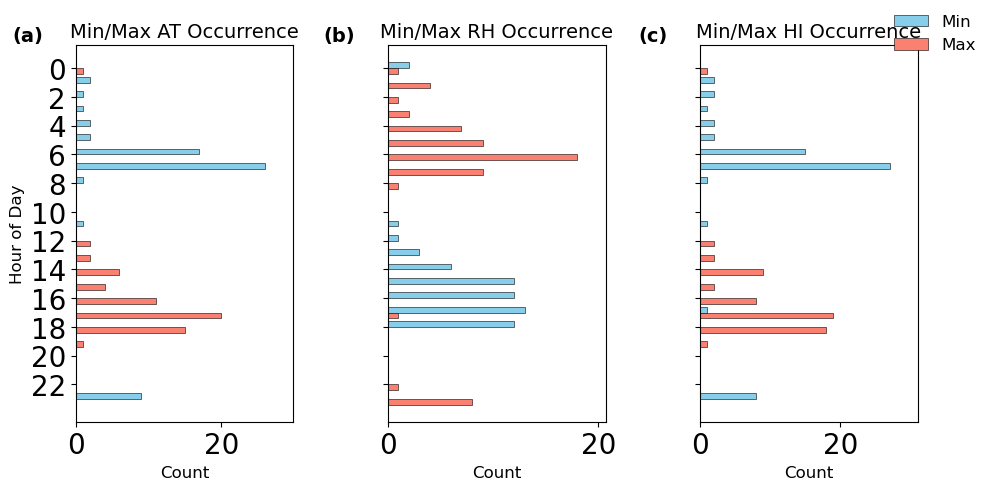

In [20]:

fig, axes = plt.subplots(1, 3, figsize=(10, 5), sharey=True)

variables = ['AT', 'RH', 'HI']
titles = [ 'Min/Max AT Occurrence','Min/Max RH Occurrence', 'Min/Max HI Occurrence']
colors = {'Min': 'skyblue', 'Max': 'salmon'}

for i, var in enumerate(variables):
    ax = axes[i]
    ax.grid(False)

    # Select relevant columns
    min_col = f'Min {var}'
    max_col = f'Max {var}'

    # Extract data and ensure 0–23 order
    df = extreme_counts[[min_col, max_col]].reindex(range(24), fill_value=0)

    # Plot side-by-side horizontal bars
    ax.barh(df.index - 0.2, df[min_col], height=0.4, color=colors['Min'],
            edgecolor='black', linewidth=0.4, label='Min')
    ax.barh(df.index + 0.2, df[max_col], height=0.4, color=colors['Max'],
            edgecolor='black', linewidth=0.4, label='Max')

    
    ax.set_xlabel('Count', fontsize=12)
    if i == 0:
        ax.set_ylabel('Hour of Day', fontsize=12)
    else:
        ax.set_yticklabels([])

    ax.invert_yaxis()
    ax.set_xlim(0, df.values.max() * 1.15)
    ax.set_yticks(range(0, 24, 2))
    ax.set_yticklabels(range(0, 24, 2))
    ax.set_title(titles[i], fontsize=14)
    # Panel labels (a, b, c)
    panel_label = chr(97 + i)
    ax.text(-0.15, 1.05, f'({panel_label})', transform=ax.transAxes,
            fontsize=14, fontweight='bold', va='top', ha='right')

# Shared legend
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right', frameon=False, fontsize=12)

plt.tight_layout(rect=[0, 0, 0.95, 1])



In [21]:
import seaborn as sns

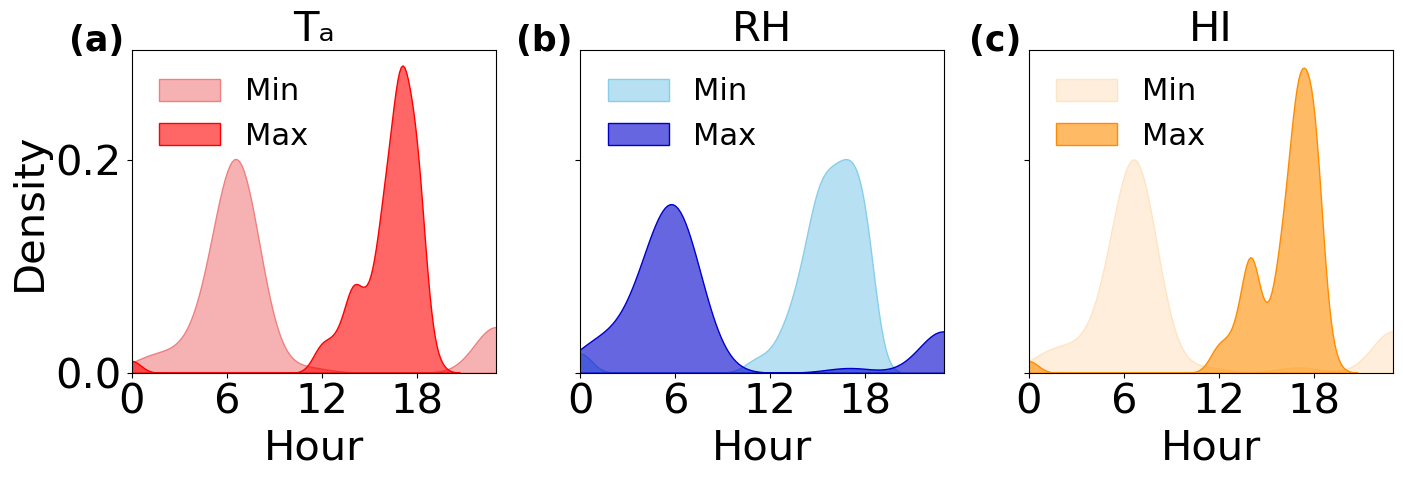

In [29]:
plt.rcParams.update({
    'font.size': 14,
    'axes.titlesize': 25,
    'axes.labelsize': 25,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20,
    'legend.fontsize': 20
})
#sns.set_style("whitegrid")

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

variables = ['AT', 'RH', 'HI']
#titles = [  'Distribution of Minimum/Maximum AT Hour', 'Distribution of Minimum/Maximum RH Hour',  'Distribution of Minimum/Maximum HI Hour']
titles = ['Tₐ', 'RH', 'HI']

colors = {'AT_Min': 'lightcoral', 'AT_Max': 'red','RH_Min': 'skyblue', 'RH_Max': 'mediumblue','HI_Min': 'bisque', 'HI_Max': 'darkorange',}

for i, var in enumerate(variables):
    ax = axes[i]
    ax.grid(False)
    # Extract min and max hour columns
    min_col = f'min_{var.lower()}_hour'
    max_col = f'max_{var.lower()}_hour'

    # KDE plots
    sns.kdeplot(at_daily_min['hour_of_min'] if var=='AT' else
                rh_daily_min['hour_of_min'] if var=='RH' else
                hi_daily_min['hour_of_min'],
                bw_adjust=0.5, fill=True, color=colors[f'{var}_Min'], alpha=0.6, label='Min', ax=ax)
    
    sns.kdeplot(at_daily_max['hour_of_max'] if var=='AT' else
                rh_daily_max['hour_of_max'] if var=='RH' else
                hi_daily_max['hour_of_max'],
                bw_adjust=0.5, fill=True, color=colors[f'{var}_Max'], alpha=0.6, label='Max', ax=ax)
    
    
    ax.set_title(titles[i], fontsize=30)
    ax.set_xlabel('Hour', fontsize=30)
    if i == 0:
        ax.set_ylabel('Density', fontsize=30)
    else:
        ax.set_ylabel('')
    
    ax.set_xlim(0, 23)
    ax.set_xticks(range(0, 24, 6))
    ax.tick_params(axis='both', labelsize=30)
    
    # Panel label
    panel_label = chr(97 + i)
    ax.text(-0.02, 1.08, f'({panel_label})', transform=ax.transAxes,
            fontsize=25, fontweight='bold', va='top', ha='right')

    ax.legend(loc = 'upper left', fontsize = 22, frameon = False)


plt.tight_layout(rect=[0, 0, 0.95, 1])
#plt.savefig('city_prediction_outputs/density_plots_occurance_of_min_max.png',transparent=True)

plt.savefig(r'C:\Users\Sarah\OneDrive - University of North Carolina at Chapel Hill\Documents\DDL\Science_Projects\Sensors\ML_model_paper\Figures\S2_density_plots.png', 
            transparent=True, bbox_inches='tight', dpi = 1200)


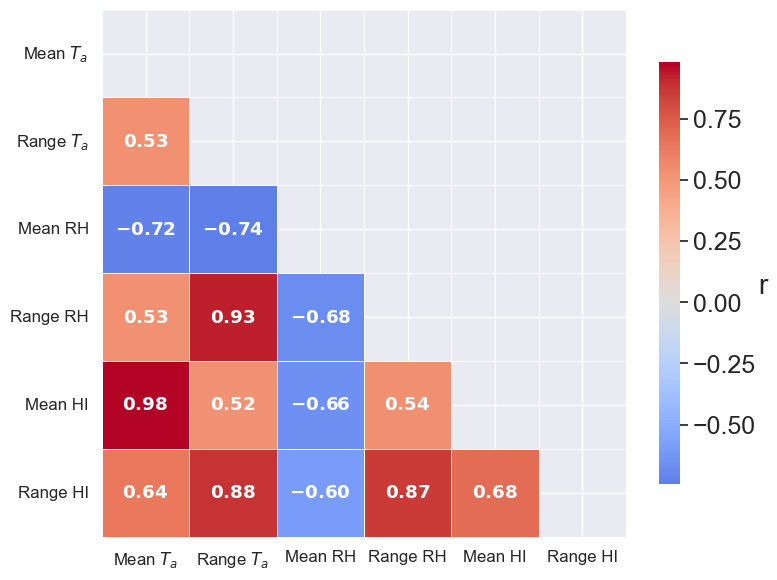

In [33]:
from scipy.stats import pearsonr

plt.rcParams.update({
    'font.size': 14,
    'axes.titlesize': 25,
    'axes.labelsize': 25,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20,
    'legend.fontsize': 22
})

# correlation matrix for the means, ranges
# Combine variables into a single DataFrame
corr_df = pd.DataFrame({
    r'Mean $T_a$': at_stats_df['mean'],
    r'Range $T_a$': at_stats_df['range'],
    'Mean RH': rh_stats_df['mean'],
    'Range RH': rh_stats_df['range'],
    'Mean HI': hi_stats_df['mean'],
    'Range HI': hi_stats_df['range']})

# Compute correlation matrix
corr_matrix = corr_df.corr()

# Compute the pvals to test for significance 
p_matrix = pd.DataFrame( np.ones_like(corr_matrix), columns=corr_matrix.columns,index=corr_matrix.index) 

for i in range(len(corr_df.columns)):
    for j in range(len(corr_df.columns)):
        r, p = pearsonr(corr_df.iloc[:, i], corr_df.iloc[:, j] )
        p_matrix.iloc[i, j] = p

# Mask for upper triangle
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# for adding correlations to the plot. Will be bold if significant based on p val < 0.05 
annot_matrix = corr_matrix.copy().astype(str)

for i in range(len(corr_matrix)):
    for j in range(len(corr_matrix)):
        r = corr_matrix.iloc[i, j]
        p = p_matrix.iloc[i, j]

        if mask[i, j]:
            annot_matrix.iloc[i, j] = ""
        else:
            if p < 0.05:
                annot_matrix.iloc[i, j] = f"$\\bf{{{r:.2f}}}$"
            else:
                annot_matrix.iloc[i, j] = f"{r:.2f}"

# Plot
plt.figure(figsize=(8, 6))
sns.set(font_scale=1.1)

ax = sns.heatmap(
    corr_matrix,
    mask=mask,
    #annot=True,
    annot=annot_matrix,
    fmt="",
    #fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8, "label": "Pearson r"}, )
# Nake labels horizontal
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, ha='right', va='center')
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=18)
cbar.set_label("r", rotation=0, labelpad=5, fontsize=20)

# Draw lines to separate AT, RH, HI blocks
#for line in [2, 4]:
#    plt.axhline(line, color='black', linewidth=1)
#    plt.axvline(line, color='black', linewidth=1)

#plt.title("Correlation Matrix: Mean and Range of AT, RH, HI", fontsize=14)
plt.tight_layout()
#plt.savefig('city_prediction_outputs/correlation_plot_mean_temp_temp_range.png',transparent=True)
plt.savefig(r'C:\Users\Sarah\OneDrive - University of North Carolina at Chapel Hill\Documents\DDL\Science_Projects\Sensors\ML_model_paper\Figures\correlation_plot_mean_temp_temp_range.png', 
            transparent=True, bbox_inches='tight', dpi = 1200)

In [72]:
at_stats_df[at_stats_df.range == at_stats_df.range.max()]

,timestamp,mean,min,max,Hour,range
112,2024-07-05 16:00:00,32.422237,28.253014,36.86649,16,8.613476


In [1]:
####################################################
##### Load rasters, clip by boundary, and plot #####
####################################################

import rasterio
import rasterio.mask
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import geopandas as gpd
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap # for plotting
 
# File paths
#max_filepath = r"D:\DDL\Durham_ML\Absolute\Summary_Rasters\July\All_Data_Trained\daily_mean_max.tif"

max_filepath = r"D:\DDL\Durham_ML\Absolute\Clipped\Summary_Rasters\AT\All_LC\daily_mean_max.tif"
min_filepath = r"D:\DDL\Durham_ML\Absolute\Clipped\Summary_Rasters\AT\All_LC\daily_mean_min.tif"
mean_filepath = r"D:\DDL\Durham_ML\Absolute\Clipped\Summary_Rasters\AT\All_LC\hourly_mean.tif"

#boundary_filepath = r"C:\Users\Sarah\Documents\Python_Scripts\DDL\Sensor_Network\Heat_model_Durham_Raleigh\data\Durham_Boundary\extent.shp"
boundary_filepath =r"C:\Users\Sarah\Documents\Python_Scripts\DDL\Sensor_Network\Heat_model_Durham_Raleigh\data\Durham_Boundary\City_of_Durham_Boundary.zip"
# Load boundary
# get the outline of the Durham boundary

durham_boundary = gpd.read_file(boundary_filepath)

#import os, glob, re
import xarray as xr

netcdf_filepath =  r"D:\DDL\Durham_ML\Absolute\Clipped\Daily_Rasters\Multibands\Durham_AT_RH_JulAug2024.nc"
multiband_ds = xr.open_dataset(netcdf_filepath)



def clip_raster(raster_path, shapes):
    """Clip raster by boundary shapefile and return array + transform."""
    with rasterio.open(raster_path) as src:
        out_image, out_transform = rasterio.mask.mask(src, durham_boundary.geometry, crop=True)
        out_meta = src.meta.copy()
    out_meta.update({
        "height": out_image.shape[1],
        "width": out_image.shape[2],
        "transform": out_transform
    })
    return out_image[0], out_meta

# Clip rasters
shapes = durham_boundary
max_arr, max_meta = clip_raster(max_filepath, shapes)
min_arr, min_meta = clip_raster(min_filepath, shapes)
mean_arr, mean_meta = clip_raster(mean_filepath, shapes)

In [34]:
import string 

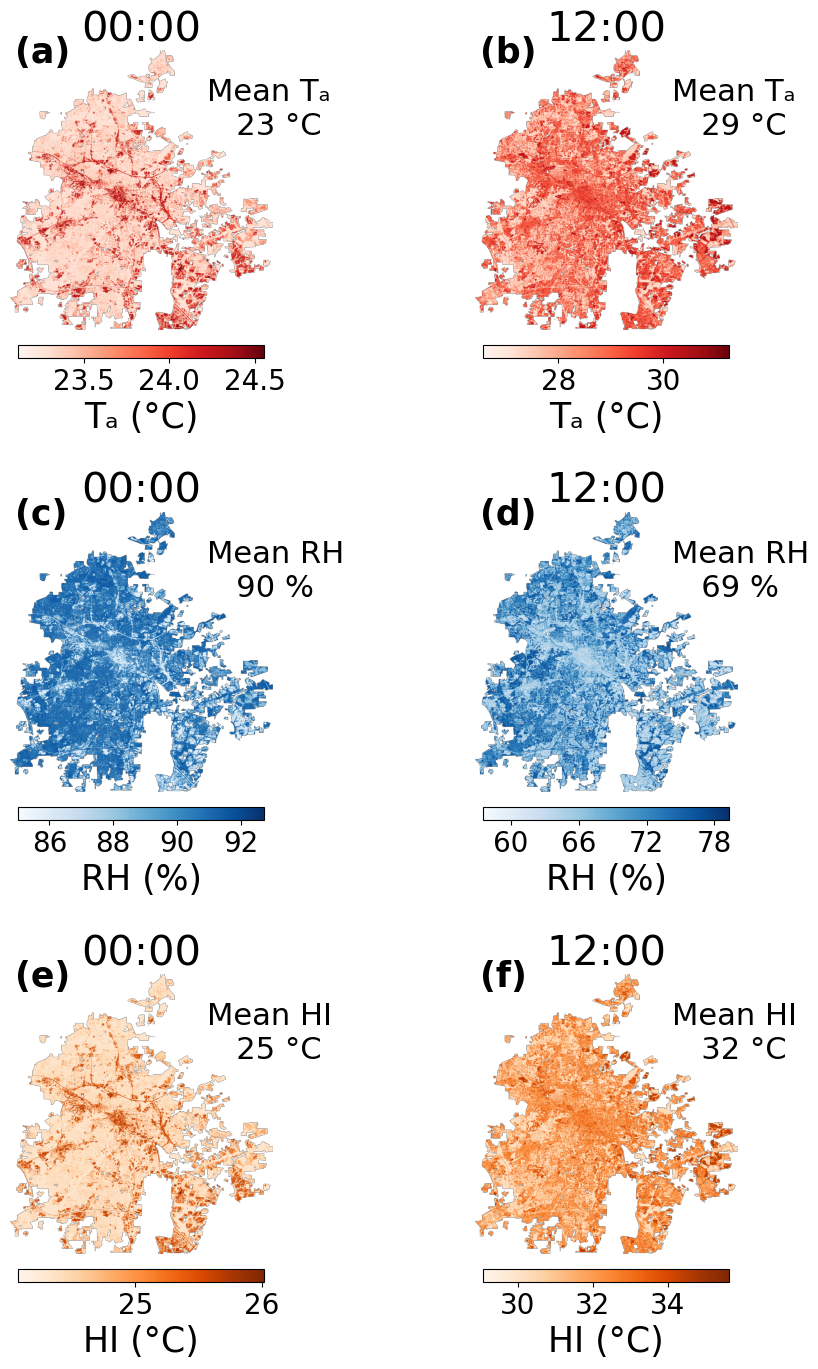

In [80]:
plt.rcParams.update({
    'font.size': 14,
    'axes.titlesize': 25,
    'axes.labelsize': 25,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20
})

## plotting the 2am, 10am, 2pm at, rh, hi
variables_to_plot = ['AT','RH','HI']
variable_labels = ['Tₐ','RH','HI']
#filenames_to_plot = ['hour_02_mean.tif','hour_10_mean.tif','hour_14_mean.tif']
#times_labels = ['2 AM', '10 AM', '2 PM']
filenames_to_plot = ['hour_00_mean.tif','hour_12_mean.tif']
times_labels = ['00:00', '12:00']
#tick_steps = { 'AT': 2,  'RH': 4,'HI': 2 } # for the color bar ticks 
tick_steps = [0.5,2,2,6,1,2]


#fig, axes = plt.subplots(3, 3, figsize=(18, 20))
fig, axes = plt.subplots(3, 2, figsize=(12, 16))
plt.subplots_adjust(wspace=0, hspace=0.5)

# get overall min and max values to have same scales on the colormaps - currently not using this 
vmin_dict = {}
vmax_dict = {}

for variable in variables_to_plot:
    all_values = []
    for filename in filenames_to_plot:
        if variable == 'HI':
            filepath = fr"D:\DDL\Durham_ML\Absolute\Clipped\Summary_Rasters\HI\{filename}"
        else:
            filepath = fr"D:\DDL\Durham_ML\Absolute\Clipped\Summary_Rasters\{variable}\All_LC\{filename}"

        with rasterio.open(filepath) as src:
            arr = src.read(1)
            arr = np.where(arr == src.nodata, np.nan, arr)
            all_values.append(arr)

    # Flatten and compute min/max ignoring NaNs
    all_concat = np.concatenate([a.flatten() for a in all_values])
    vmin_dict[variable] = np.nanmin(all_concat)
    vmax_dict[variable] = np.nanmax(all_concat)

# Subplot labels 
label_counter = 0
subplot_labels = list(string.ascii_lowercase)


for i, (variable, var_label) in enumerate(zip(variables_to_plot, variable_labels)):
    for j, filename in enumerate(filenames_to_plot):

        # determine filepath and color scheme
        if variable == 'HI':
            filepath = fr"D:\DDL\Durham_ML\Absolute\Clipped\Summary_Rasters\HI\{filename}"
            colormap = 'Oranges'
            units = '°C'
        else:
            filepath = fr"D:\DDL\Durham_ML\Absolute\Clipped\Summary_Rasters\{variable}\All_LC\{filename}"
            if variable == 'AT':
                colormap = 'Reds'
                units = '°C'
            elif variable == 'RH':
                colormap = 'Blues'
                units = '%'

        # read the raster
        with rasterio.open(filepath) as src:
            arr = src.read(1)
            arr = np.where(arr == src.nodata, np.nan, arr)

        vmin = np.nanmin(arr)
        vmax = np.nanmax(arr)
        mean_val = np.nanmean(arr)

        
        # Plot
        ax = axes[i, j]
        im = ax.imshow(arr, cmap=colormap,vmin=vmin, vmax=vmax) #vmin=vmin_dict[variable], vmax=vmax_dict[variable])
        ax.axis("off")

        # Add text with subplot letter label
        ax.text(
            0.02, 1.05,
            f"({subplot_labels[label_counter]})",
            transform=ax.transAxes,
            fontsize=25,
            fontweight="bold",
            va="top", ha="left"
        )
        label_counter += 1
        
        # Add textwith the mean value for each variable (using this when the colorbar scales change, to aid comparison across times of day)
        ax.text(
            0.75, 0.9, 
            f"Mean {var_label}\n   {mean_val:.0f} {units}", 
            color="black", 
            fontsize=22,
            #fontweight='bold',
            ha='left', va='top',
            transform=ax.transAxes,
            bbox=dict(facecolor='white', alpha=0.6, edgecolor='none', boxstyle='round,pad=0.3')
        )

        
        # Set subplot titles
        #if i == 0:
        #    ax.set_title(times_labels[j], fontsize=30)
        ax.set_title(times_labels[j], fontsize=30)
        if j == 0:
            ax.set_ylabel(var_label, fontsize=30, rotation=0, labelpad=60)

        # Add colorbar below each plot
        cbar = fig.colorbar(im, ax=ax, orientation="horizontal", fraction=0.04, pad=0.05)
        cbar.set_label(f"{var_label} ({units})", fontsize=25)
        #step = tick_steps[variable]
        step = tick_steps[label_counter - 1]
        cbar.ax.xaxis.set_major_locator(MultipleLocator(step))

#plt.savefig('city_prediction_outputs/spatial_pattern_means_hours_2_10_14.png',transparent=True)
#plt.savefig('city_prediction_outputs/spatial_pattern_means_hours_00_12.png',transparent=True)

plt.savefig(r'C:\Users\Sarah\OneDrive - University of North Carolina at Chapel Hill\Documents\DDL\Science_Projects\Sensors\ML_model_paper\spatial_pattern_means_hours_00_12.png', 
            format='png', dpi=1200, bbox_inches='tight')